# Metastatic Breast Cancer Detection from Histopathology Images using Deep Learning

**Course:** Healthcare Analytics (21CSE428T)  
**Dataset:** PatchCamelyon (PCam)  
**Domain:** Biomedical Image Analysis / Digital Pathology  
**Task:** Binary classification — metastatic tissue vs. non-metastatic tissue

### Project objective
Build and evaluate a deep-learning system that classifies 96×96 histopathology image patches as:
- **0 — Non-metastatic**
- **1 — Metastatic**

The notebook is structured to connect the project with **Tutorial/Unit 1 and Unit 2 concepts** from the Healthcare Analytics syllabus: EHR concepts, healthcare-data preprocessing, biomedical image preprocessing, feature extraction, classification, visualization, and discussion of healthcare-data challenges.

> **Important:** This is an academic ML/DL project. Model predictions are not medical diagnoses.

## 1. Dataset and project justification

**PatchCamelyon (PCam)** contains **327,680 color images of size 96×96 pixels** extracted from histopathologic scans of lymph-node sections. Each image has a binary label indicating whether metastatic tissue is present.

Official dataset:  
https://patchcamelyon.grand-challenge.org/

Torchvision provides a built-in `PCAM` dataset loader with train/validation/test splits and automatic downloading.

### Why this project fits the course
| Course area | How it appears in this project |
|---|---|
| Healthcare Data Analytics | Clinical/pathology data is converted into measurable computational features |
| EHR / healthcare-data concepts | Data quality, missing/redundant information, standardization and privacy are discussed |
| Biomedical Image Analysis | Histopathology image preprocessing and analysis |
| Image enhancement / restoration | Resize/normalization and optional augmentation |
| Feature extraction | CNN layers learn visual features automatically |
| Classification | Binary metastatic/non-metastatic classification |
| Visualization | Class distribution, image grids, training curves, confusion matrix, ROC and Grad-CAM |
| Healthcare challenges | Class imbalance, staining variation, false positives/negatives, generalization and explainability |

# 2. Tutorial 1 — Understanding Healthcare Data / EHR

### Key concepts to know for viva

**Electronic Health Record (EHR):** a digital collection of patient-related health information used by healthcare providers.

Typical EHR components can include:
- demographics
- diagnoses
- medications
- laboratory results
- vital signs
- clinical notes
- imaging reports
- procedures
- allergies
- encounter information

### Why EHR and biomedical images are both healthcare data
Healthcare analytics is not limited to tables. Healthcare data can be:
- **structured:** age, lab values, diagnosis codes
- **semi-structured:** coded records and metadata
- **unstructured:** clinical notes
- **multimedia:** X-rays, CT, MRI, pathology images, ECG signals

PCam is an example of **biomedical image data** rather than an EHR table.

### Important healthcare-data challenges
1. Privacy and security
2. Missing or inconsistent data
3. Different data standards
4. Data quality and noise
5. Dataset bias
6. Class imbalance
7. Interoperability
8. Explainability and clinical trust

### Connection to this project
Although PCam does not provide patient-level EHR fields, the same healthcare-analytics principles apply to the image dataset: **data quality, preprocessing, representation, validation, bias, privacy, and reliable interpretation.**

# 3. Tutorial 2 — Preprocessing of Healthcare Data

The syllabus emphasizes:
- **standardization**
- **data cleaning**
- **redundant-data removal**
- **missing-data handling**

For an image dataset, preprocessing is different from tabular EHR preprocessing, but the underlying objective is the same: make the input consistent and suitable for analysis.

### EHR preprocessing mapping

| EHR concept | Image-project equivalent |
|---|---|
| Standardization | Normalize image pixel values |
| Data cleaning | Detect invalid/corrupt samples and inconsistent inputs |
| Missing values | Check missing labels/files; image tensors must have valid dimensions |
| Redundant data | Avoid duplicate/near-duplicate leakage between splits |
| Feature engineering | Hand-crafted features or learned CNN representations |
| Train/test separation | Keep evaluation data unseen during training |

### Small EHR-style preprocessing demonstration
The following example is **synthetic and is not an additional project dataset**. It is included only to demonstrate Tutorial 2 concepts for viva.

In [ ]:
import pandas as pd
import numpy as np

ehr_demo = pd.DataFrame({
    "patient_id": [101, 102, 103, 103, 104],
    "age": [45, 61, np.nan, np.nan, 50],
    "systolic_bp": [130, 145, 150, 150, 128],
    "cholesterol": [210, 250, 230, 230, 190]
})

print("Original synthetic EHR-style table:")
display(ehr_demo)

# 1. Remove exact duplicate records
ehr_clean = ehr_demo.drop_duplicates()

# 2. Handle missing numeric values using median imputation
for col in ["age", "systolic_bp", "cholesterol"]:
    ehr_clean[col] = ehr_clean[col].fillna(ehr_clean[col].median())

# 3. Standardization example: z-score
for col in ["age", "systolic_bp", "cholesterol"]:
    mean = ehr_clean[col].mean()
    std = ehr_clean[col].std()
    ehr_clean[col + "_z"] = (ehr_clean[col] - mean) / std

print("After duplicate removal, missing-value handling and standardization:")
display(ehr_clean)

Original synthetic EHR-style table:


,patient_id,age,systolic_bp,cholesterol
0,101,45.0,130,210
1,102,61.0,145,250
2,103,NaN,150,230
3,103,NaN,150,230
4,104,50.0,128,190


After duplicate removal, missing-value handling and standardization:


/tmp/ipykernel_1508/3955411487.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ehr_clean[col] = ehr_clean[col].fillna(ehr_clean[col].median())
/tmp/ipykernel_1508/3955411487.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ehr_clean[col + "_z"] = (ehr_clean[col] - mean) / std
/tmp/ipykernel_1508/3955411487.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: h

,patient_id,age,systolic_bp,cholesterol,age_z,systolic_bp_z,cholesterol_z
0,101,45.0,130,210,-0.961864,-0.756541,-0.387298
1,102,61.0,145,250,1.405801,0.618988,1.161895
2,103,50.0,150,230,-0.221969,1.077498,0.387298
4,104,50.0,128,190,-0.221969,-0.939945,-1.161895


## 4. Unit 2 — Biomedical Image Analysis

The syllabus includes:
- image acquisition
- image enhancement/restoration
- image segmentation
- image registration
- feature extraction
- biomedical image analysis
- image visualization
- sensor/image-data challenges

### How PCam maps to Unit 2

**Input → preprocessing → feature extraction → classification → visualization**

For PCam:
1. Histopathology images are already provided as 96×96 patches.
2. Pixel values are converted into tensors and normalized.
3. Augmentation improves robustness to image variation.
4. CNN layers learn low-level and high-level visual features.
5. A classification head predicts metastatic/non-metastatic tissue.
6. Metrics and Grad-CAM provide visual/model interpretation.

### Important distinction
PCam is a **classification** dataset. We are not claiming to perform full whole-slide-image segmentation. We classify image patches according to their supplied binary labels.

# 5. Tutorial 4/5/6 concepts used in the implementation

### Image preprocessing
We use:
- resizing where required by the model
- normalization
- training-time augmentation such as horizontal/vertical flips and small rotations

### Feature extraction
CNNs learn hierarchical representations:
- early layers → edges/textures
- middle layers → tissue patterns
- deeper layers → higher-level discriminative patterns

### Visualization
We will generate:
- representative PCam image grids
- class distribution
- training/validation loss and accuracy curves
- confusion matrix
- ROC curve
- misclassified examples
- Grad-CAM heatmaps

These visualizations give material for the **Results & Discussion** mark.

In [ ]:
# ============================
# 6. Install / import packages
# ============================
!pip -q install gdown h5py scikit-learn seaborn

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.models import ResNet18_Weights

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve
)

print("PyTorch:", torch.__version__)
print("Device:", "CUDA GPU" if torch.cuda.is_available() else "CPU")

PyTorch: 2.11.0+cu128
Device: CUDA GPU


In [ ]:
# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE

device(type='cuda')

In [ ]:
device = DEVICE

print("Training device:", device)

Training device: cuda


# 7. Download and load PCam

The official PCam benchmark has 327,680 color 96×96 images with binary metastatic-tissue labels. Torchvision's `PCAM` loader supports `train`, `val`, and `test` splits and can download the dataset automatically.

**Storage/time note:** The full dataset is large. For a classroom Colab demonstration, the notebook defaults to a configurable subset. Set the sample limits to `None` if you have enough runtime/storage and want to train on all available samples.

### Alternative Dataset Download
If the official torchvision download fails due to Google Drive limits, use the Kaggle API to download the dataset. You will need to provide your Kaggle username and key.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# LOAD THE PCam DATASET FROM THE KAGGLE DOWNLOAD
# ============================================================

import os
import glob
import zipfile

DATA_ROOT = "/content/pcam_data"
os.makedirs(DATA_ROOT, exist_ok=True)

# Find the large PCam ZIP downloaded earlier
zip_files = glob.glob("/content/**/*.zip", recursive=True)

print("ZIP files found:")
for f in zip_files:
    size_gb = os.path.getsize(f) / (1024**3)
    print(f"  {f}  ({size_gb:.2f} GB)")

# Find PCam ZIP
pcam_zip = None

for f in zip_files:
    if "patchcamelyon" in os.path.basename(f).lower():
        pcam_zip = f
        break

if pcam_zip is None:
    raise FileNotFoundError(
        "PCam ZIP was not found. Run the Kaggle download cell again."
    )

print("\nPCam ZIP found:")
print(pcam_zip)

print("\nExtracting PCam...")
print("This may take several minutes.")

with zipfile.ZipFile(pcam_zip, "r") as zip_ref:
    zip_ref.extractall(DATA_ROOT)

print("\n✅ PCam extracted successfully!")
print("Location:", DATA_ROOT)

ZIP files found:
  /content/metastatic-tissue-classification-patchcamelyon.zip  (7.47 GB)
  /content/drive/MyDrive/archive (4).zip  (0.06 GB)

PCam ZIP found:
/content/metastatic-tissue-classification-patchcamelyon.zip

Extracting PCam...
This may take several minutes.

✅ PCam extracted successfully!
Location: /content/pcam_data


In [ ]:
# Check what was extracted

import os

for root, dirs, files in os.walk(DATA_ROOT):
    level = root.replace(DATA_ROOT, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    if level >= 2:
        dirs[:] = []

    for file in files[:5]:
        print(f"{indent}  {file}")

pcam_data/
  Metadata/
    Metadata/
      train_metadata.csv
      test_metadata.csv
      valid_metadata.csv
  pcam/
    test_split.h5
    training_split.h5
    validation_split.h5
  camelyonpatch_level_2_split_train_mask/
    camelyonpatch_level_2_split_train_mask.h5
  Labels/
    Labels/
      camelyonpatch_level_2_split_train_y.h5
      camelyonpatch_level_2_split_test_y.h5
      camelyonpatch_level_2_split_valid_y.h5


Checking files...

Train images:
  /content/pcam_data/pcam/training_split.h5
  Exists: True

Validation images:
  /content/pcam_data/pcam/validation_split.h5
  Exists: True

Test images:
  /content/pcam_data/pcam/test_split.h5
  Exists: True

Train labels:
  /content/pcam_data/Labels/Labels/camelyonpatch_level_2_split_train_y.h5
  Exists: True

Validation labels:
  /content/pcam_data/Labels/Labels/camelyonpatch_level_2_split_valid_y.h5
  Exists: True

Test labels:
  /content/pcam_data/Labels/Labels/camelyonpatch_level_2_split_test_y.h5
  Exists: True


HDF5 datasets found:
Train X : x
Val X   : x
Test X  : x
Train Y : y
Val Y   : y
Test Y  : y

PCam datasets created successfully
Training samples  : 20000
Validation samples: 3000
Test samples      : 3000

First sample:
Image type : <class 'numpy.ndarray'>
Image shape: (96, 96, 3)
Image dtype: uint8
Label      : 0


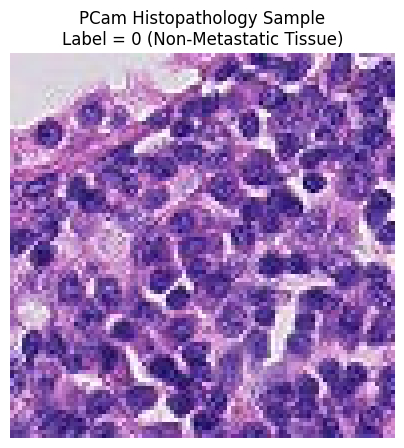

In [ ]:
# ============================================================
# PCam - COMPLETE DATA LOADER
# Run this cell from top to bottom
# ============================================================

import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

DATA_ROOT = "/content/pcam_data"


# ------------------------------------------------------------
# 1. Locate HDF5 files automatically
# ------------------------------------------------------------

TRAIN_X_PATH = os.path.join(
    DATA_ROOT, "pcam", "training_split.h5"
)

VAL_X_PATH = os.path.join(
    DATA_ROOT, "pcam", "validation_split.h5"
)

TEST_X_PATH = os.path.join(
    DATA_ROOT, "pcam", "test_split.h5"
)

# Search for label files instead of assuming exact folder depth
def find_file(root, filename):
    for current_root, dirs, files in os.walk(root):
        if filename in files:
            return os.path.join(current_root, filename)
    return None


TRAIN_Y_PATH = find_file(
    DATA_ROOT,
    "camelyonpatch_level_2_split_train_y.h5"
)

VAL_Y_PATH = find_file(
    DATA_ROOT,
    "camelyonpatch_level_2_split_valid_y.h5"
)

TEST_Y_PATH = find_file(
    DATA_ROOT,
    "camelyonpatch_level_2_split_test_y.h5"
)


print("Checking files...\n")

paths = {
    "Train images": TRAIN_X_PATH,
    "Validation images": VAL_X_PATH,
    "Test images": TEST_X_PATH,
    "Train labels": TRAIN_Y_PATH,
    "Validation labels": VAL_Y_PATH,
    "Test labels": TEST_Y_PATH
}

for name, path in paths.items():
    print(f"{name}:")
    print(f"  {path}")
    print(f"  Exists: {os.path.exists(path) if path else False}\n")


# ------------------------------------------------------------
# 2. Find dataset name inside HDF5
# ------------------------------------------------------------

def find_h5_dataset(filepath):

    if filepath is None:
        raise FileNotFoundError("HDF5 file path is None.")

    datasets = []

    with h5py.File(filepath, "r") as f:

        def visitor(name, obj):

            if isinstance(obj, h5py.Dataset):
                datasets.append(name)

        f.visititems(visitor)

    if not datasets:
        raise ValueError(
            f"No dataset found inside {filepath}"
        )

    return datasets[0]


train_x_key = find_h5_dataset(TRAIN_X_PATH)
val_x_key   = find_h5_dataset(VAL_X_PATH)
test_x_key  = find_h5_dataset(TEST_X_PATH)

train_y_key = find_h5_dataset(TRAIN_Y_PATH)
val_y_key   = find_h5_dataset(VAL_Y_PATH)
test_y_key  = find_h5_dataset(TEST_Y_PATH)


print("\nHDF5 datasets found:")
print("Train X :", train_x_key)
print("Val X   :", val_x_key)
print("Test X  :", test_x_key)
print("Train Y :", train_y_key)
print("Val Y   :", val_y_key)
print("Test Y  :", test_y_key)


# ------------------------------------------------------------
# 3. Lightweight PCam Dataset
# ------------------------------------------------------------

class PCamDataset:

    def __init__(self, image_path, image_key,
                 label_path, label_key,
                 max_samples=None):

        self.image_path = image_path
        self.image_key = image_key

        self.label_path = label_path
        self.label_key = label_key

        # Read only shape — NOT the whole dataset
        with h5py.File(self.image_path, "r") as f:
            total_images = f[self.image_key].shape[0]

        with h5py.File(self.label_path, "r") as f:
            total_labels = f[self.label_key].shape[0]

        self.length = min(total_images, total_labels)

        if max_samples is not None:
            self.length = min(
                self.length,
                max_samples
            )

        self._image_file = None
        self._label_file = None

    def _open_files(self):

        if self._image_file is None:

            self._image_file = h5py.File(
                self.image_path,
                "r"
            )

            self._label_file = h5py.File(
                self.label_path,
                "r"
            )

    def __len__(self):
        return self.length

    def __getitem__(self, index):

        self._open_files()

        image = self._image_file[
            self.image_key
        ][index]

        label = self._label_file[
            self.label_key
        ][index]

        # Convert label to scalar
        label = int(np.asarray(label).squeeze())

        return image, label


# ------------------------------------------------------------
# 4. Create datasets
# ------------------------------------------------------------

# Start small so Colab remains fast.
TRAIN_SAMPLES = 20000
VAL_SAMPLES   = 3000
TEST_SAMPLES  = 3000


raw_train = PCamDataset(
    TRAIN_X_PATH,
    train_x_key,
    TRAIN_Y_PATH,
    train_y_key,
    max_samples=TRAIN_SAMPLES
)

raw_val = PCamDataset(
    VAL_X_PATH,
    val_x_key,
    VAL_Y_PATH,
    val_y_key,
    max_samples=VAL_SAMPLES
)

raw_test = PCamDataset(
    TEST_X_PATH,
    test_x_key,
    TEST_Y_PATH,
    test_y_key,
    max_samples=TEST_SAMPLES
)


print("\n===================================")
print("PCam datasets created successfully")
print("===================================")

print("Training samples  :", len(raw_train))
print("Validation samples:", len(raw_val))
print("Test samples      :", len(raw_test))


# ------------------------------------------------------------
# 5. Inspect first image
# ------------------------------------------------------------

sample_img, sample_label = raw_train[0]

print("\nFirst sample:")
print("Image type :", type(sample_img))
print("Image shape:", sample_img.shape)
print("Image dtype:", sample_img.dtype)
print("Label      :", sample_label)


plt.figure(figsize=(5, 5))

plt.imshow(sample_img)

if sample_label == 0:
    title = "Non-Metastatic Tissue"
else:
    title = "Metastatic Tissue"

plt.title(
    f"PCam Histopathology Sample\n"
    f"Label = {sample_label} ({title})"
)

plt.axis("off")
plt.show()

Non-metastatic     9915
Metastatic        10085
Name: count, dtype: int64


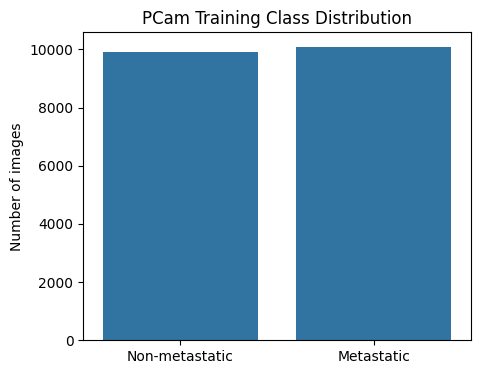

In [ ]:
# ============================
# 8. Dataset exploration
# ============================
def get_labels(dataset, max_items=None):
    n = len(dataset) if max_items is None else min(len(dataset), max_items)
    labels = []
    for i in range(n):
        _, y = dataset[i]
        labels.append(int(y))
    return np.array(labels)

# Use all labels for PCam because labels are inexpensive to read.
train_labels_all = get_labels(raw_train)
val_labels_all = get_labels(raw_val)
test_labels_all = get_labels(raw_test)

def show_distribution(labels, title):
    counts = pd.Series(labels).value_counts().sort_index()
    print(counts.rename(index={0:"Non-metastatic", 1:"Metastatic"}))
    plt.figure(figsize=(5,4))
    sns.countplot(x=labels)
    plt.xticks([0,1], ["Non-metastatic", "Metastatic"])
    plt.title(title)
    plt.ylabel("Number of images")
    plt.show()

show_distribution(train_labels_all, "PCam Training Class Distribution")

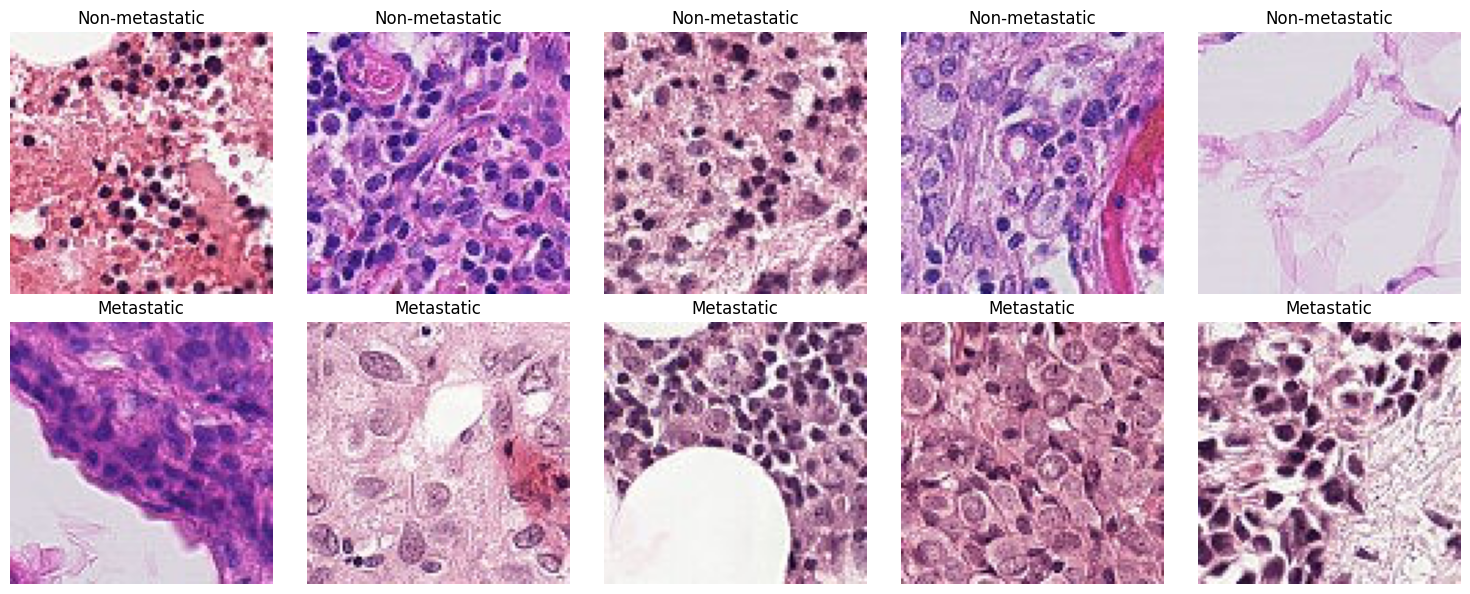

In [ ]:
# Display a balanced grid of representative images
def show_image_grid(dataset, labels, n_per_class=5):
    indices = []
    for cls in [0, 1]:
        cls_idx = np.where(labels == cls)[0]
        chosen = np.random.choice(cls_idx, size=n_per_class, replace=False)
        indices.extend(chosen.tolist())

    fig, axes = plt.subplots(2, n_per_class, figsize=(15, 6))
    for j, idx in enumerate(indices):
        img, y = dataset[idx]
        ax = axes[int(y), j % n_per_class]
        ax.imshow(img)
        ax.set_title("Metastatic" if int(y)==1 else "Non-metastatic")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_image_grid(raw_train, train_labels_all, n_per_class=5)

## 9. Train/validation/test strategy

The official PCam splits are used:
- **Train:** used for model fitting
- **Validation:** used for hyperparameter/model selection
- **Test:** kept for final evaluation

For the classroom run we sample a fixed number of examples from each split to reduce training time. This does **not** change the project definition; it is a computational shortcut for Colab.

If reporting the subset experiment, explicitly state the number of images used.

In [ ]:
# ============================================================
# CREATE EXPERIMENT SUBSETS
# ============================================================

import numpy as np
from torch.utils.data import Subset

MAX_TRAIN_SAMPLES = 20000
MAX_VAL_SAMPLES = 3000
MAX_TEST_SAMPLES = 3000

SEED = 42


def make_subset(dataset, max_samples, seed=42):

    if max_samples is None or max_samples >= len(dataset):
        return dataset

    rng = np.random.default_rng(seed)

    indices = rng.choice(
        len(dataset),
        size=max_samples,
        replace=False
    )

    return Subset(dataset, indices.tolist())


train_base = make_subset(
    raw_train,
    MAX_TRAIN_SAMPLES,
    SEED
)

val_base = make_subset(
    raw_val,
    MAX_VAL_SAMPLES,
    SEED
)

test_base = make_subset(
    raw_test,
    MAX_TEST_SAMPLES,
    SEED
)


print("Experiment sizes:")
print("Train:", len(train_base))
print("Validation:", len(val_base))
print("Test:", len(test_base))

Experiment sizes:
Train: 20000
Validation: 3000
Test: 3000


# 11. Baseline CNN

A small CNN gives us a baseline. This is useful for the **Methodology** and **Results & Discussion** marks because we can compare a conventional CNN with transfer learning.

In [ ]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1,1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

baseline_model = BaselineCNN().to(DEVICE)
print(baseline_model)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=Tru

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:

        images = images.to(device)

        labels = labels.float().view(-1, 1).to(device)

        optimizer.zero_grad()

        outputs = model(images)

        outputs = outputs.view(-1, 1)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        probs = torch.sigmoid(outputs)

        predictions = (probs >= 0.5).long()

        total_correct += (
            predictions.squeeze(1)
            == labels.squeeze(1).long()
        ).sum().item()

        total_samples += images.size(0)

    avg_loss = running_loss / total_samples

    accuracy = total_correct / total_samples

    return avg_loss, accuracy

In [ ]:
def evaluate(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    all_probs = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # Keep original integer labels for metrics
            original_labels = labels.clone()

            # BCEWithLogitsLoss expects [batch, 1]
            labels = labels.float().view(-1, 1).to(device)

            outputs = model(images)

            # Make output shape [batch, 1]
            outputs = outputs.view(-1, 1)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            # Convert logits → probability
            probs = torch.sigmoid(outputs)

            predictions = (probs >= 0.5).long()

            total_correct += (
                predictions.squeeze(1).cpu()
                == original_labels
            ).sum().item()

            total_samples += images.size(0)

            all_probs.extend(
                probs.squeeze(1).cpu().numpy()
            )

            all_labels.extend(
                original_labels.cpu().numpy()
            )

    avg_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "probs": np.array(all_probs),
        "labels": np.array(all_labels)
    }

In [ ]:
def fit_model(model, train_loader, val_loader, epochs=3, lr=1e-3):

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):

        # -------------------------------
        # Training
        # -------------------------------

        tr_loss, tr_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        # -------------------------------
        # Validation
        # -------------------------------

        val_metrics = evaluate(
            model,
            val_loader,
            criterion
        )

        # -------------------------------
        # Store results
        # -------------------------------

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)

        history["val_loss"].append(
            val_metrics["loss"]
        )

        history["val_acc"].append(
            val_metrics["accuracy"]
        )

        # -------------------------------
        # Print progress
        # -------------------------------

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {tr_loss:.4f} | "
            f"Train Acc: {tr_acc:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Val Acc: {val_metrics['accuracy']:.4f}"
        )

    return history

In [ ]:
# ============================================================
# CREATE PYTORCH DATALOADERS
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import numpy as np


# ------------------------------------------------------------
# Image transformations
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.ToPILImage(),

    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


eval_transform = transforms.Compose([
    transforms.ToPILImage(),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# PyTorch wrapper
# ------------------------------------------------------------

class PCamTorchDataset(Dataset):

    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):

        image, label = self.dataset[index]

        # Convert numpy image to uint8
        image = np.asarray(image).astype(np.uint8)

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            int(label),
            dtype=torch.long
        )

        return image, label


# ------------------------------------------------------------
# Create transformed datasets
# ------------------------------------------------------------

train_dataset = PCamTorchDataset(
    train_base,
    transform=train_transform
)

val_dataset = PCamTorchDataset(
    val_base,
    transform=eval_transform
)

test_dataset = PCamTorchDataset(
    test_base,
    transform=eval_transform
)


# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ------------------------------------------------------------
# Check one batch
# ------------------------------------------------------------

images, labels = next(iter(train_loader))

print("DataLoaders created successfully!")
print()
print("Image batch shape :", images.shape)
print("Label batch shape :", labels.shape)
print("Image dtype       :", images.dtype)
print("Label dtype       :", labels.dtype)
print("Labels            :", labels[:10].tolist())

DataLoaders created successfully!

Image batch shape : torch.Size([64, 3, 96, 96])
Label batch shape : torch.Size([64])
Image dtype       : torch.float32
Label dtype       : torch.int64
Labels            : [1, 1, 0, 0, 1, 0, 0, 1, 1, 1]


In [ ]:
# Train baseline CNN
BASELINE_EPOCHS = 3

baseline_history = fit_model(
    baseline_model,
    train_loader,
    val_loader,
    epochs=BASELINE_EPOCHS,
    lr=1e-3
)

Epoch 1/3 | Train Loss: 0.3494 | Train Acc: 0.8526 | Val Loss: 0.4263 | Val Acc: 0.8117
Epoch 2/3 | Train Loss: 0.3335 | Train Acc: 0.8582 | Val Loss: 0.4433 | Val Acc: 0.7907
Epoch 3/3 | Train Loss: 0.3272 | Train Acc: 0.8604 | Val Loss: 0.4249 | Val Acc: 0.8087


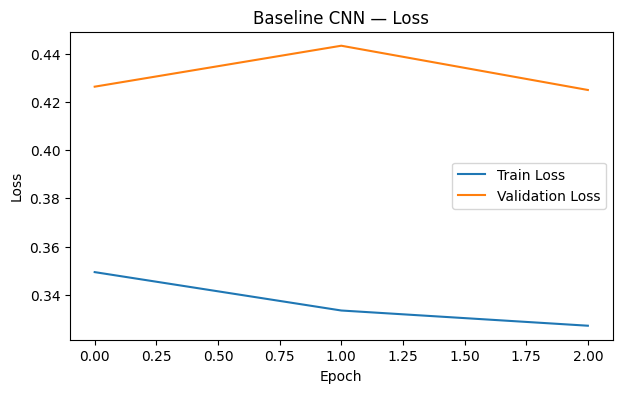

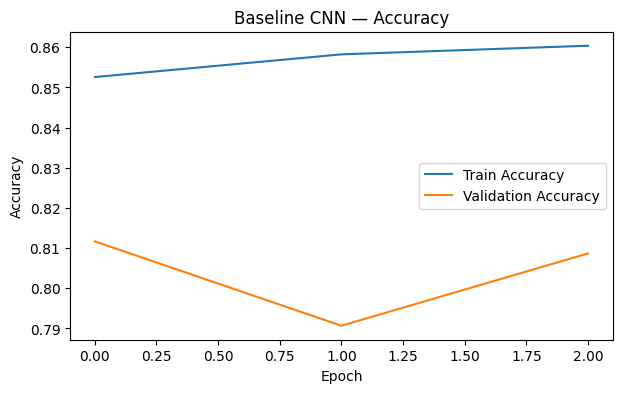

In [ ]:
def plot_history(history, title_prefix="Model"):
    fig, ax = plt.subplots(figsize=(7,4))
    ax.plot(history["train_loss"], label="Train Loss")
    ax.plot(history["val_loss"], label="Validation Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title(f"{title_prefix} — Loss")
    ax.legend()
    plt.show()

    fig, ax = plt.subplots(figsize=(7,4))
    ax.plot(history["train_acc"], label="Train Accuracy")
    ax.plot(history["val_acc"], label="Validation Accuracy")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.set_title(f"{title_prefix} — Accuracy")
    ax.legend()
    plt.show()

plot_history(baseline_history, "Baseline CNN")

In [ ]:
# ============================================================
# BASELINE CNN - TEST SET EVALUATION
# ============================================================

criterion = nn.BCEWithLogitsLoss()

baseline_metrics = evaluate(
    baseline_model,
    test_loader,
    criterion
)

print("Baseline CNN test metrics")
print("-" * 40)

print(f"Test Loss     : {baseline_metrics['loss']:.4f}")
print(f"Test Accuracy : {baseline_metrics['accuracy']:.4f}")

Baseline CNN test metrics
----------------------------------------
Test Loss     : 0.4854
Test Accuracy : 0.7790


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_true_b = baseline_metrics["labels"]
y_prob_b = baseline_metrics["probs"]
y_pred_b = (y_prob_b >= 0.5).astype(int)

print("\nDetailed Baseline CNN Results")
print("=" * 45)

print(
    f"Accuracy  : {accuracy_score(y_true_b, y_pred_b):.4f}"
)

print(
    f"Precision : {precision_score(y_true_b, y_pred_b):.4f}"
)

print(
    f"Recall    : {recall_score(y_true_b, y_pred_b):.4f}"
)

print(
    f"F1 Score  : {f1_score(y_true_b, y_pred_b):.4f}"
)

print(
    f"ROC-AUC   : {roc_auc_score(y_true_b, y_prob_b):.4f}"
)

print("\nClassification Report:")
print(
    classification_report(
        y_true_b,
        y_pred_b,
        target_names=[
            "Non-Metastatic",
            "Metastatic"
        ]
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_true_b,
        y_pred_b
    )
)


Detailed Baseline CNN Results
Accuracy  : 0.7790
Precision : 0.9192
Recall    : 0.6352
F1 Score  : 0.7512
ROC-AUC   : 0.9015

Classification Report:
                precision    recall  f1-score   support

Non-Metastatic       0.70      0.94      0.80      1424
    Metastatic       0.92      0.64      0.75      1576

      accuracy                           0.78      3000
     macro avg       0.81      0.79      0.78      3000
  weighted avg       0.81      0.78      0.77      3000


Confusion Matrix:
[[1336   88]
 [ 575 1001]]


# 13. Transfer Learning with ResNet18

For the main model, we use **ResNet18 pretrained on ImageNet** and replace its final classification layer with a binary classifier.

This demonstrates:
- transfer learning
- deep feature extraction
- fine-tuning
- biomedical image classification

For a stronger academic project, compare this model against the baseline CNN rather than reporting only one model.

In [ ]:
# ============================
# 14. ResNet18 transfer learning
# ============================
weights = ResNet18_Weights.DEFAULT
resnet = models.resnet18(weights=weights)

# Replace the final classifier for binary classification
num_features = resnet.fc.in_features
resnet.fc = nn.Linear(num_features, 1)

resnet = resnet.to(DEVICE)
print(resnet.fc)

Linear(in_features=512, out_features=1, bias=True)


In [ ]:
# ============================================================
# RESNET18 TRANSFER LEARNING
# ============================================================

import torch
import torch.nn as nn
from torchvision import models


# ------------------------------------------------------------
# Create ResNet18
# ------------------------------------------------------------

resnet = models.resnet18(weights="DEFAULT")

# Replace final classification layer
resnet.fc = nn.Linear(
    resnet.fc.in_features,
    1
)

resnet = resnet.to(device)


# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

criterion = nn.BCEWithLogitsLoss()


# ------------------------------------------------------------
# First train only classification head
# ------------------------------------------------------------

for name, param in resnet.named_parameters():
    param.requires_grad = name.startswith("fc")


optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, resnet.parameters()),
    lr=1e-3
)


HEAD_EPOCHS = 1

for epoch in range(HEAD_EPOCHS):

    tr_loss, tr_acc = train_one_epoch(
        resnet,
        train_loader,
        criterion,
        optimizer
    )

    print(
        f"Head Epoch {epoch + 1}/{HEAD_EPOCHS} | "
        f"Train Loss: {tr_loss:.4f} | "
        f"Train Acc: {tr_acc:.4f}"
    )


# ------------------------------------------------------------
# Unfreeze complete network
# ------------------------------------------------------------

for param in resnet.parameters():
    param.requires_grad = True


# Smaller learning rate for fine-tuning
optimizer = torch.optim.Adam(
    resnet.parameters(),
    lr=1e-4
)


# ------------------------------------------------------------
# Fine-tune
# ------------------------------------------------------------

FINE_TUNE_EPOCHS = 3

history_resnet = fit_model(
    resnet,
    train_loader,
    val_loader,
    epochs=FINE_TUNE_EPOCHS,
    lr=1e-4
)

print("\n✅ ResNet18 fine-tuning completed.")

Head Epoch 1/1 | Train Loss: 0.4963 | Train Acc: 0.7605
Epoch 1/3 | Train Loss: 0.3292 | Train Acc: 0.8599 | Val Loss: 0.3560 | Val Acc: 0.8527
Epoch 2/3 | Train Loss: 0.2508 | Train Acc: 0.8982 | Val Loss: 0.4094 | Val Acc: 0.8227
Epoch 3/3 | Train Loss: 0.2118 | Train Acc: 0.9177 | Val Loss: 0.3105 | Val Acc: 0.8787

✅ ResNet18 fine-tuning completed.


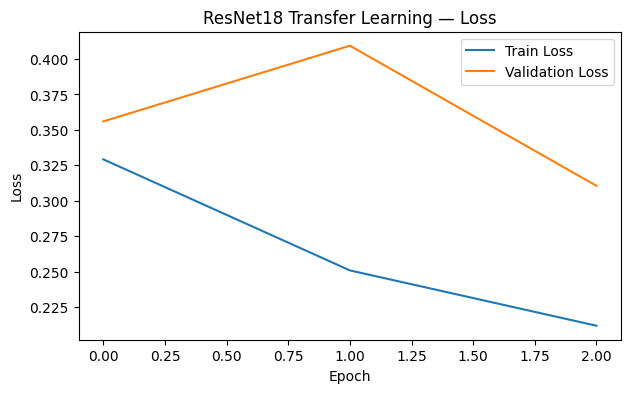

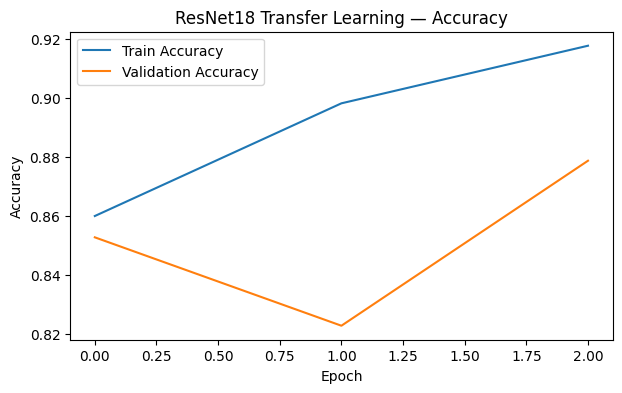

In [ ]:
plot_history(history_resnet, "ResNet18 Transfer Learning")

In [ ]:
# ============================================================
# RESNET18 - TEST SET EVALUATION
# ============================================================

criterion = nn.BCEWithLogitsLoss()

resnet_metrics = evaluate(
    resnet,
    test_loader,
    criterion
)

print("ResNet18 test metrics")
print("-" * 40)

print(f"Test Loss     : {resnet_metrics['loss']:.4f}")
print(f"Test Accuracy : {resnet_metrics['accuracy']:.4f}")

ResNet18 test metrics
----------------------------------------
Test Loss     : 0.4006
Test Accuracy : 0.8383


In [ ]:
# ============================================================
# RESNET18 - DETAILED METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_true = resnet_metrics["labels"]
y_prob = resnet_metrics["probs"]

y_pred = (y_prob >= 0.5).astype(int)

print("\nDetailed ResNet18 Results")
print("=" * 45)

print(f"Accuracy  : {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision : {precision_score(y_true, y_pred):.4f}")
print(f"Recall    : {recall_score(y_true, y_pred):.4f}")
print(f"F1 Score  : {f1_score(y_true, y_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_true, y_prob):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Non-Metastatic",
            "Metastatic"
        ]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))


Detailed ResNet18 Results
Accuracy  : 0.8383
Precision : 0.9272
Recall    : 0.7513
F1 Score  : 0.8300
ROC-AUC   : 0.9356

Classification Report:
                precision    recall  f1-score   support

Non-Metastatic       0.77      0.93      0.85      1424
    Metastatic       0.93      0.75      0.83      1576

      accuracy                           0.84      3000
     macro avg       0.85      0.84      0.84      3000
  weighted avg       0.85      0.84      0.84      3000


Confusion Matrix:
[[1331   93]
 [ 392 1184]]


# 15. Results and discussion

The following section produces the core evidence for the **Results & Discussion** mark.

Interpretation:
- **Accuracy:** overall fraction classified correctly.
- **Precision:** among predicted metastatic patches, how many were actually metastatic.
- **Recall/Sensitivity:** among actual metastatic patches, how many were detected.
- **F1-score:** harmonic mean of precision and recall.
- **ROC-AUC:** ranking/discrimination ability across classification thresholds.

For a healthcare application, do not discuss accuracy alone. False negatives and false positives have different implications, so precision/recall and the confusion matrix should also be discussed.

In [ ]:
# Compare the two models
results = pd.DataFrame([
    {"Model": "Baseline CNN", **{k:v for k,v in baseline_metrics.items() if v is not None}},
    {"Model": "ResNet18", **{k:v for k,v in resnet_metrics.items() if v is not None}}
])

display(results.style.format({
    "loss":"{:.4f}", "accuracy":"{:.4f}", "precision":"{:.4f}",
    "recall":"{:.4f}", "f1":"{:.4f}", "roc_auc":"{:.4f}"
}))

,Model,loss,accuracy,probs,labels
0,Baseline CNN,0.4854,0.7790,[0.05945487 0.543976 0.5442107 ... 0.9999933 0.9180427 0.18628477],[0 1 0 ... 1 1 1]
1,ResNet18,0.4006,0.8383,[0.00459798 0.999637 0.79433274 ... 0.9999999 0.9856396 0.05037491],[0 1 0 ... 1 1 1]


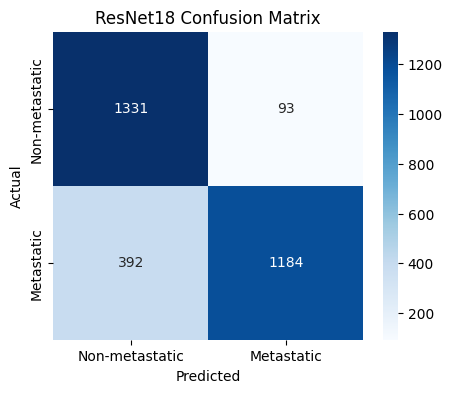

                precision    recall  f1-score   support

Non-metastatic     0.7725    0.9347    0.8459      1424
    Metastatic     0.9272    0.7513    0.8300      1576

      accuracy                         0.8383      3000
     macro avg     0.8498    0.8430    0.8379      3000
  weighted avg     0.8538    0.8383    0.8375      3000



In [ ]:
# Confusion matrix for the main model
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Non-metastatic", "Metastatic"],
    yticklabels=["Non-metastatic", "Metastatic"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet18 Confusion Matrix")
plt.show()

print(classification_report(
    y_true, y_pred,
    target_names=["Non-metastatic", "Metastatic"],
    digits=4
))

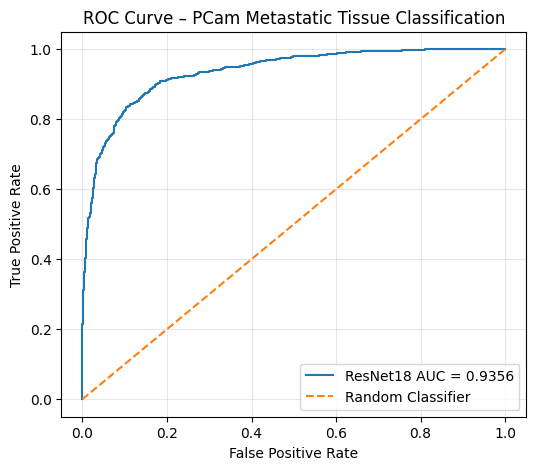

ResNet18 ROC-AUC: 0.9356


In [ ]:
# ============================================================
# ROC CURVE - ResNet18
# ============================================================

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get true labels and predicted probabilities
y_true = resnet_metrics["labels"]
y_prob = resnet_metrics["probs"]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

# Calculate ROC-AUC
resnet_auc = roc_auc_score(
    y_true,
    y_prob
)

# Plot
plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ResNet18 AUC = {resnet_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve – PCam Metastatic Tissue Classification"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"ResNet18 ROC-AUC: {resnet_auc:.4f}")

# 16. Misclassified-image analysis

Looking at wrong predictions is useful for the **discussion** section.

Questions to discuss:
- Are errors concentrated in visually ambiguous patches?
- Are there staining/background variations?
- Does the model confuse normal tissue with small metastatic regions?
- Are there systematic patterns in false positives/false negatives?

Never claim a visual pattern is medically causal unless it has been clinically validated.

Number of test errors: 485


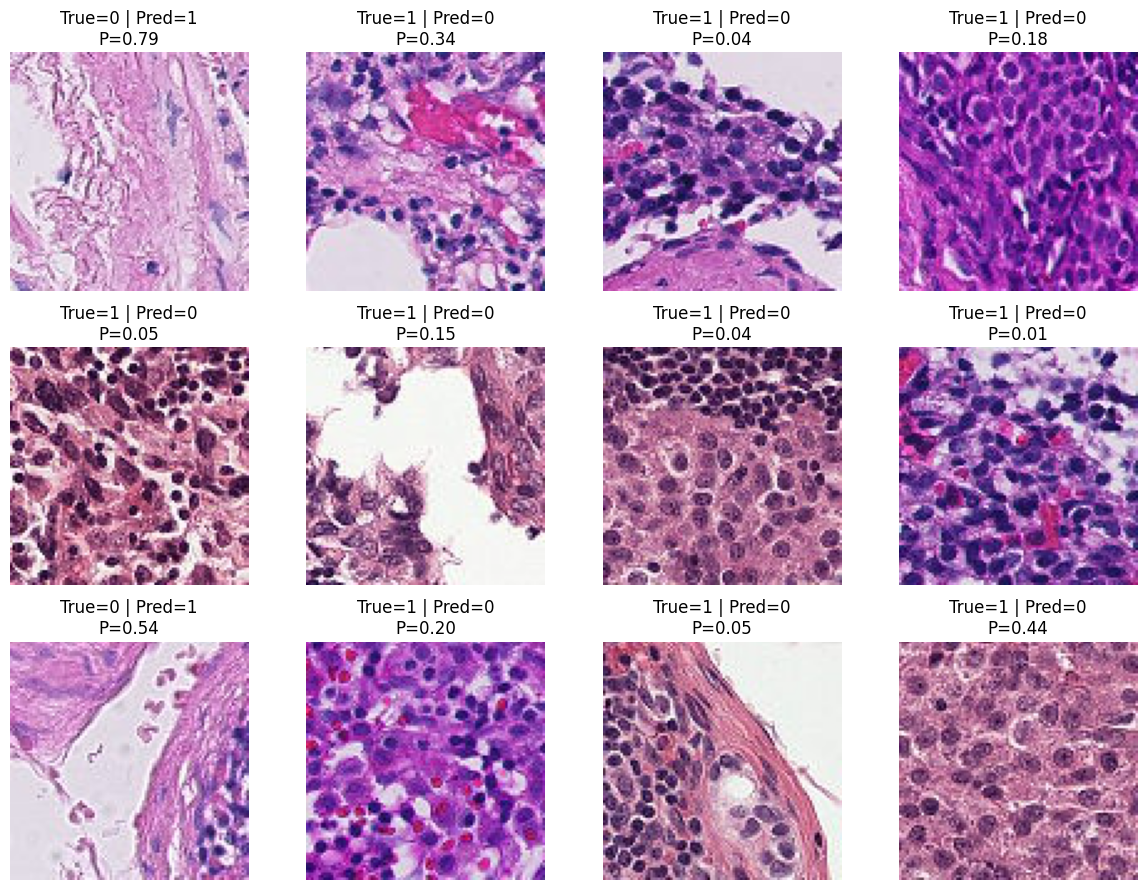

In [ ]:
# Show a sample of misclassified test images
def denormalize(t):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return (t.cpu() * std + mean).clamp(0,1)

wrong = np.where(y_true != y_pred)[0]
print("Number of test errors:", len(wrong))

# Collect up to 12 examples
n_show = min(12, len(wrong))
fig, axes = plt.subplots(3, 4, figsize=(12,9))
axes = axes.flatten()

# Need to iterate through the deterministic test loader in order
all_images = []
all_targets = []
for x, y in test_loader:
    all_images.append(x)
    all_targets.append(y)

all_images = torch.cat(all_images)
all_targets = torch.cat(all_targets).numpy()

for ax, idx in zip(axes, wrong[:n_show]):
    img = denormalize(all_images[idx]).permute(1,2,0).numpy()
    ax.imshow(img)
    ax.set_title(f"True={y_true[idx]} | Pred={y_pred[idx]}\nP={y_prob[idx]:.2f}")
    ax.axis("off")

for ax in axes[n_show:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 17. Grad-CAM — model explainability

Grad-CAM provides a coarse localization map showing image regions that contribute to a CNN's prediction.

This is useful for discussing:
- model interpretability
- explainable AI
- clinical trust
- limitations of black-box prediction

A Grad-CAM heatmap is **not** a medical annotation and should not be interpreted as a clinically validated lesion segmentation.

In [ ]:
# ============================
# 18. Grad-CAM implementation
# ============================
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(self.save_activation)
        self.backward_handle = target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, inp, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def __call__(self, x):
        self.model.zero_grad()
        output = self.model(x)
        score = output[:, 0].sum()
        score.backward()

        weights = self.gradients.mean(dim=(2,3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = torch.nn.functional.interpolate(
            cam, size=x.shape[-2:], mode="bilinear", align_corners=False
        )

        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

    def close(self):
        self.forward_handle.remove()
        self.backward_handle.remove()

# Last convolutional block in ResNet18
target_layer = resnet.layer4[-1].conv2
gradcam = GradCAM(resnet, target_layer)

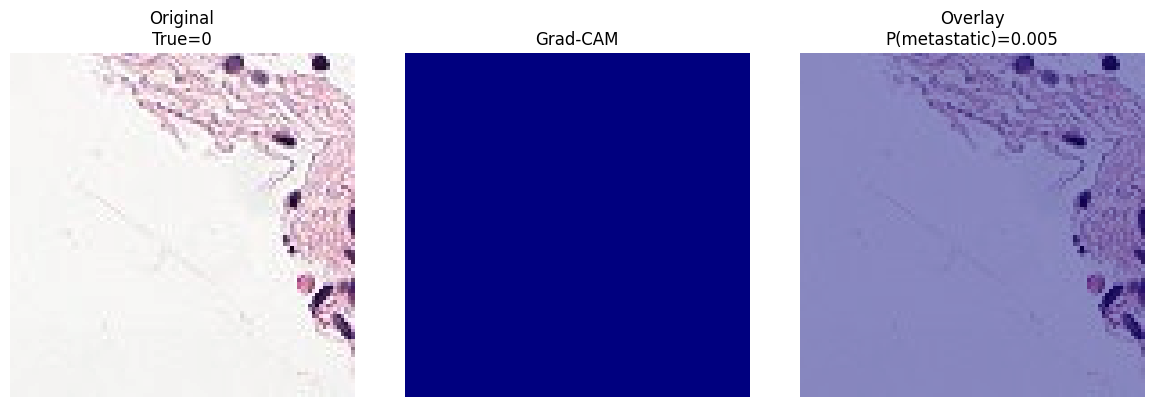

In [ ]:
# Select one test image
x_batch, y_batch = next(iter(test_loader))
idx = 0

x_one = x_batch[idx:idx+1].to(DEVICE)
true_label = int(y_batch[idx])

with torch.no_grad():
    probability = torch.sigmoid(resnet(x_one)).item()

# Need gradients, so do this outside no_grad
cam = gradcam(x_one)

original = denormalize(x_one[0]).permute(1,2,0).numpy()

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(original)
plt.title(f"Original\nTrue={true_label}")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(original)
plt.imshow(cam, cmap="jet", alpha=0.45)
plt.title(f"Overlay\nP(metastatic)={probability:.3f}")
plt.axis("off")

plt.tight_layout()
plt.show()

# 19. Innovation / quality-of-work component

To strengthen the 1-mark **Quality of Project Work / Innovation** criterion, the project includes:

1. **Baseline vs. transfer-learning comparison**
2. **Data augmentation**
3. **Multiple evaluation metrics**
4. **Confusion-matrix and error analysis**
5. **ROC-AUC analysis**
6. **Grad-CAM explainability**

### Optional extensions
If time permits:
- Compare ResNet18 with EfficientNet-B0 or MobileNetV3.
- Use class-weighted loss if imbalance becomes significant.
- Perform stain/color augmentation.
- Add calibration analysis.
- Compare frozen-feature extraction vs. full fine-tuning.
- Perform patient/slide-aware evaluation if appropriate metadata is available.

# 20. Healthcare limitations and ethical discussion

A strong healthcare project must discuss limitations.

### Dataset limitations
- PCam consists of image patches rather than complete patient records.
- Patch-level labels do not automatically represent a complete clinical diagnosis.
- Histopathology appearance can vary across laboratories, scanners and staining protocols.
- Model performance on PCam does not guarantee performance on another hospital's data.

### Clinical limitations
- False negatives and false positives must be considered separately.
- A model should be externally validated before clinical use.
- Human pathologist oversight is essential in real clinical workflows.
- Privacy, governance and responsible data handling are required for patient data.

### Responsible conclusion
The project demonstrates a **research/educational classification pipeline**, not an autonomous diagnostic system.

# 21. Final conclusion

### Expected project pipeline

**PCam Histopathology Images**  
↓  
**Image preprocessing + augmentation**  
↓  
**CNN / ResNet18 feature extraction**  
↓  
**Binary classification**  
↓  
**Metastatic vs. Non-metastatic**  
↓  
**Accuracy + Precision + Recall + F1 + ROC-AUC**  
↓  
**Confusion Matrix + Error Analysis + Grad-CAM**

### Final presentation statement
> "We developed a deep-learning pipeline for binary classification of PatchCamelyon histopathology image patches. The project integrates biomedical image preprocessing, learned feature extraction, transfer learning, quantitative evaluation, error analysis and explainability, while discussing the healthcare-data challenges and limitations relevant to real-world deployment."

# 22. Viva questions and short answers

**Q1. What is PCam?**  
PatchCamelyon is a biomedical image classification benchmark containing 96×96 histopathology patches from lymph-node sections, labelled for presence/absence of metastatic tissue.

**Q2. Why use CNNs?**  
CNNs learn spatially local visual patterns such as edges, textures and higher-level tissue structures.

**Q3. Why normalization?**  
It puts input values into a consistent numerical range/distribution and helps neural-network optimization.

**Q4. Why augmentation?**  
It exposes the model to plausible image variations and can reduce overfitting.

**Q5. Why ResNet18?**  
It provides a proven convolutional architecture with residual connections and can use transfer learning.

**Q6. Why use recall in healthcare?**  
Recall measures how many actual positive cases are detected. Missing a positive case is a false negative, so sensitivity can be important depending on the application.

**Q7. What is Grad-CAM?**  
A visualization technique that uses gradients from a CNN to highlight image regions that contributed to a prediction.

**Q8. What is the difference between Unit 1 and Unit 2 here?**  
Unit 1 gives healthcare-data/EHR concepts and preprocessing principles; Unit 2 focuses on biomedical image analysis, preprocessing, feature extraction and visualization.

**Q9. Is this a medical diagnostic system?**  
No. It is an academic research prototype and requires external validation and clinical oversight before any clinical use.

# 23. References

1. PatchCamelyon — Official dataset: https://patchcamelyon.grand-challenge.org/
2. Torchvision PCAM documentation: https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.PCAM.html
3. Veeling, B. S. et al., *Rotation Equivariant CNNs for Digital Pathology*, arXiv:1806.03962.
4. Ehteshami Bejnordi et al., *Diagnostic Assessment of Deep Learning Algorithms for Detection of Lymph Node Metastases in Women With Breast Cancer*, JAMA, 2017.

**Dataset citation:** cite the PCam benchmark and its original paper in the final report/PPT.